In [75]:
from standard_imports import *
from loaders import index
from ModelSimlink import RadiativeTransitions
from plots import splt
from Tools import LinesManipulator
from scipy.optimize import curve_fit

In [76]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )
data = [ data[4], data[12] ]

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

In [77]:
worker = LinesManipulator.LinesManipulator()

In [78]:
lines = [ '2p2->1s5', '2p2->1s4', '2p2->1s2', '2p3->1s5', '2p3->1s4', '2p4->1s5', '2p4->1s3', '2p4->1s2', '2p6->1s5', '2p6->1s2', '2p10->1s5', '2p10->1s4' ]
colors = { k: v for v, k in zip( plt.list_colors(), ['2p1','2p2','2p3','2p4','2p5','2p6','2p7','2p8','2p9','2p10'] ) }

In [79]:
lines_calib = [ l for l in RadiativeTransitions.RadiativeTransitions().linesList() if f"{l['from']}->{l['to']}" in lines ]

Realigned with y = -0.00x^2 +1.00x -0.18
Realigned with y = 0.00x^2 +1.00x +0.90


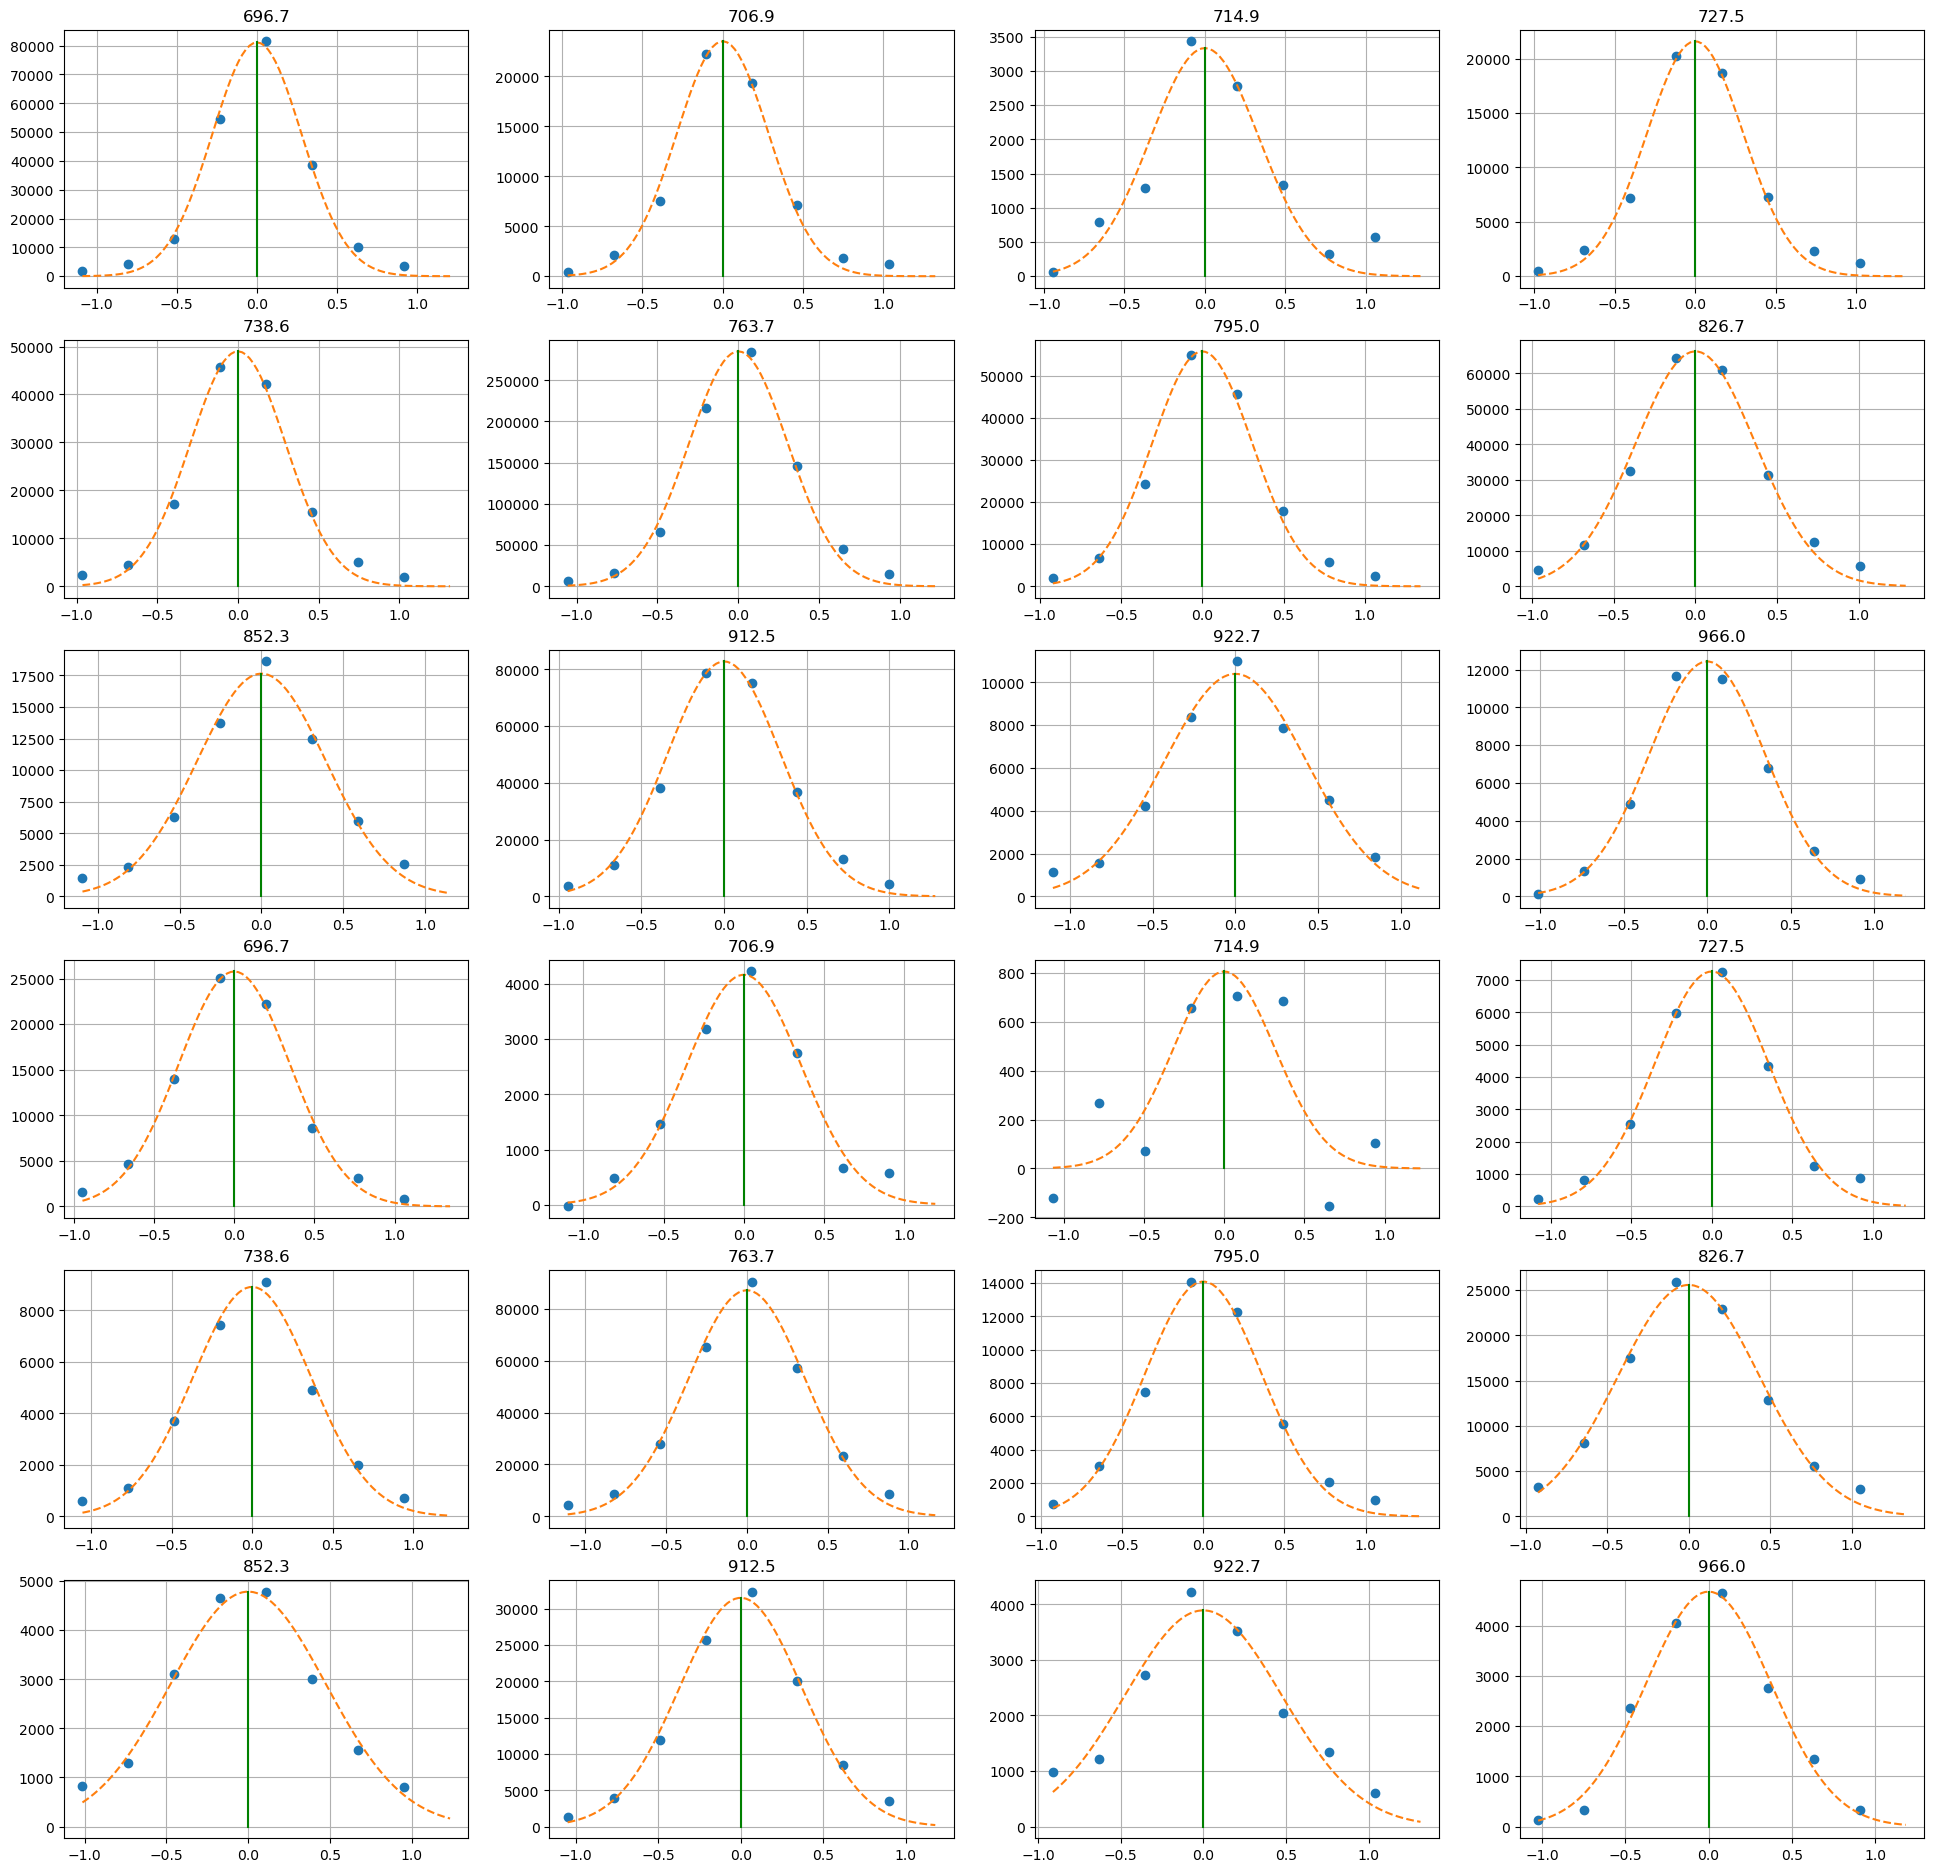

In [80]:
splt.init_bytot( 100 )

for d in data:

    wl = worker.realign_wl( d['avantes']['wl'], d['avantes']['int'] )
    d['realigned_wls'] = wl
    intt = np.array( d['avantes']['int'] ) - np.mean( d['avantes']['int'][:185] )
    d['den_dict'] = {}

    for l in lines_calib:
        
        splt.next()
        ampl = worker.estimate_amplitude( wl - l['wl'], intt, True )
        plt.title(f"{l['wl']:.1f}")
        if( ampl > 0 ):
            if( l['from'] not in d['den_dict'].keys() ):
                d['den_dict'][ l['from'] ] = []
            d['den_dict'][ l['from'] ].append( { 'wl': l['wl'], 'den': ampl / l['A'], 'code': f"{l['from']}->{l['to']}" } )

In [81]:
for d in data:
    print( f"=== {d['ID']} ===" )
    for lv in d['den_dict'].keys():
        print( lv, ": ", [ f"{l['wl']:.1f}" for l in d['den_dict'][lv] ] )

=== 13 ===
2p2 :  ['696.7', '727.5', '826.7']
2p3 :  ['706.9', '738.6']
2p4 :  ['714.9', '795.0', '852.3']
2p6 :  ['763.7', '922.7']
2p10 :  ['912.5', '966.0']
=== 105 ===
2p2 :  ['696.7', '727.5', '826.7']
2p3 :  ['706.9', '738.6']
2p4 :  ['714.9', '795.0', '852.3']
2p6 :  ['763.7', '922.7']
2p10 :  ['912.5', '966.0']


In [82]:
d['den_dict'][lv]

[{'wl': 912.516153405404, 'den': 0.001552809819276021, 'code': '2p10->1s5'},
 {'wl': 966.0107429308281, 'den': 0.0008198513783029147, 'code': '2p10->1s4'}]

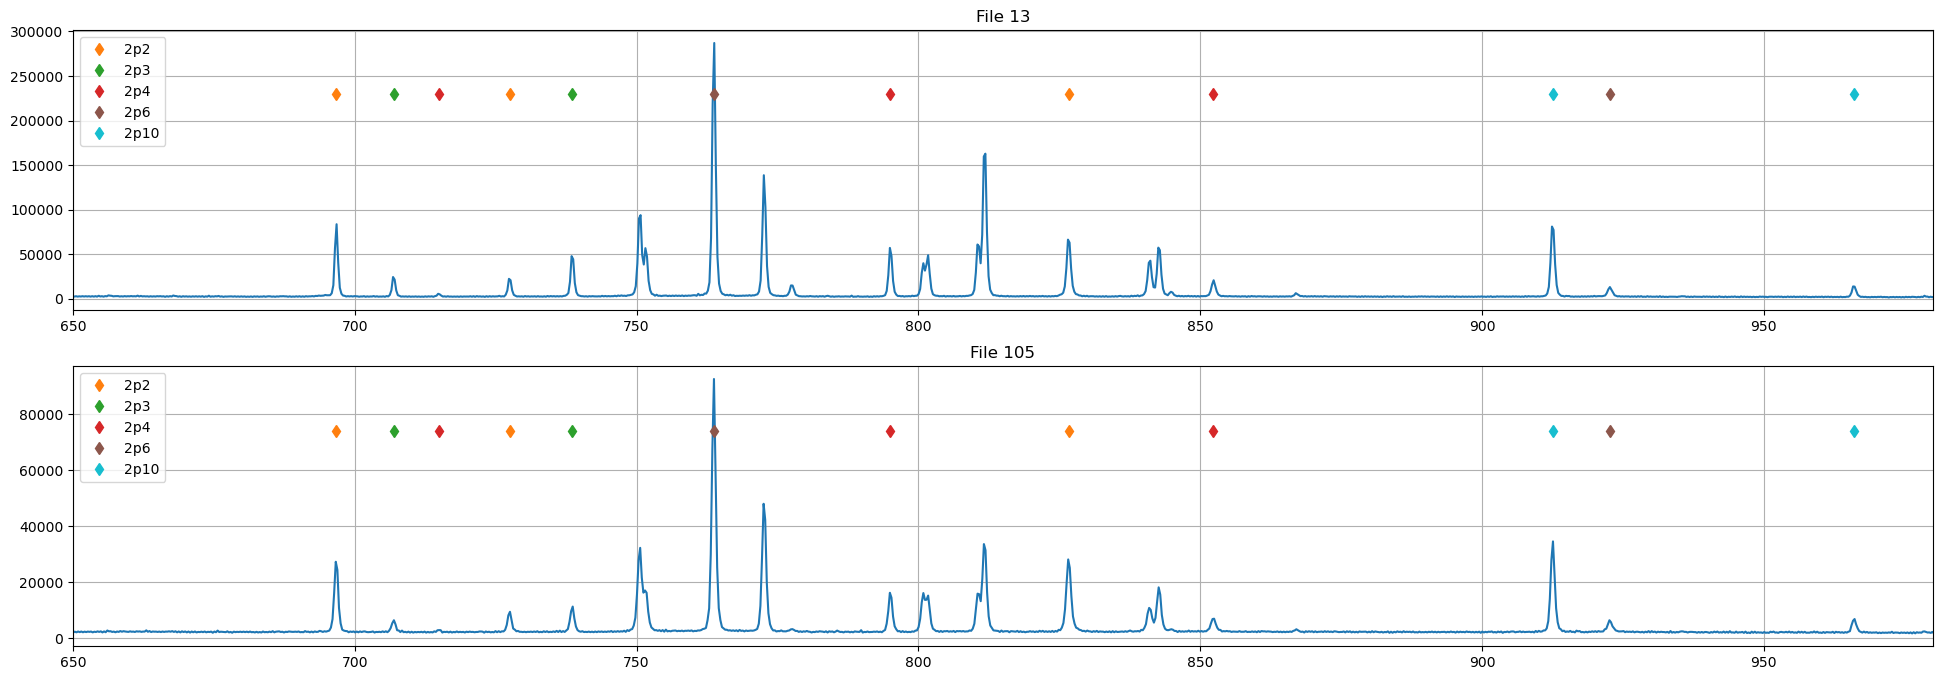

In [83]:
splt.init_bytot( len( data ), 1, size = ( 24, 4 ))

for d in data:
    splt.next()
    plt.plot( d['realigned_wls'], d['avantes']['int'] )
    hh = np.max( d['avantes']['int'] ) * 0.8
    for lv in d['den_dict'].keys():
        plt.plot( [ l['wl'] for l in d['den_dict'][lv] ], np.ones_like( d['den_dict'][lv] ) * hh, 'd', color = colors[lv], label = lv)
    plt.xlim( 650, 980 )
    plt.legend( loc = 'upper left')
    # worker.realign_wl( d['avantes']['wl'], d['avantes']['int'], True )
    plt.title(f"File {d['ID']}")

====
====
====
====
====
====
====
====


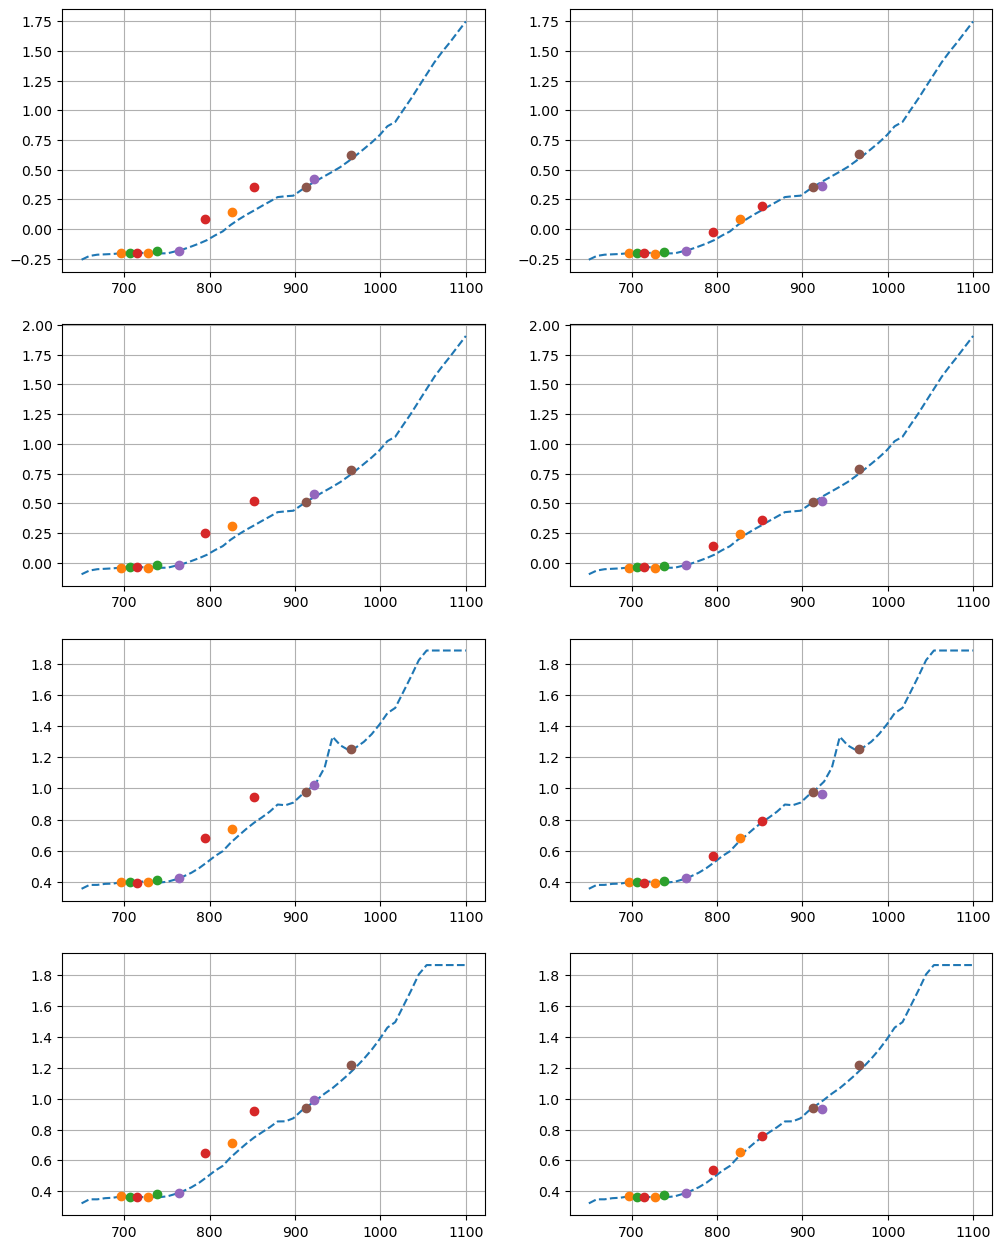

In [84]:
xs = np.linspace( 650, 1100 )

splt.init( len( data ) * 4, 2 )

for file in glob( 'CalibrationData/*.csv' ):
    calib_spectrum = pd.read_csv(file, index_col = False).to_dict('list')
    theocal = np.log10( np.interp( xs, calib_spectrum['wl'], calib_spectrum['f_normalized'] ) )
    for d in data:
        splt.next()

        plt.plot( xs, theocal, '--' )

        print('====')
        for lv in d['den_dict'].keys():
            if( len( d['den_dict'][lv] ) > 1 ):
                wls = [ l['wl'] for l in d['den_dict'][lv] ]
                kkk = - np.log10( np.array( [ l['den'] for l in d['den_dict'][lv] ] ) )
                kkk = kkk + ( np.interp( wls[0], xs, theocal ) - kkk[0] )
                
                plt.plot( wls, kkk, 'o' )

[ 7.75345330e-04 -2.54000322e-01  1.79909109e+00  2.09489927e+00
  2.15820297e+00  1.68265437e+00  1.46026838e+00]
[1.66176913e-04 6.72644206e-01 1.71097568e+00 2.25901905e+00
 2.26490035e+00 1.68272944e+00 1.49129943e+00]


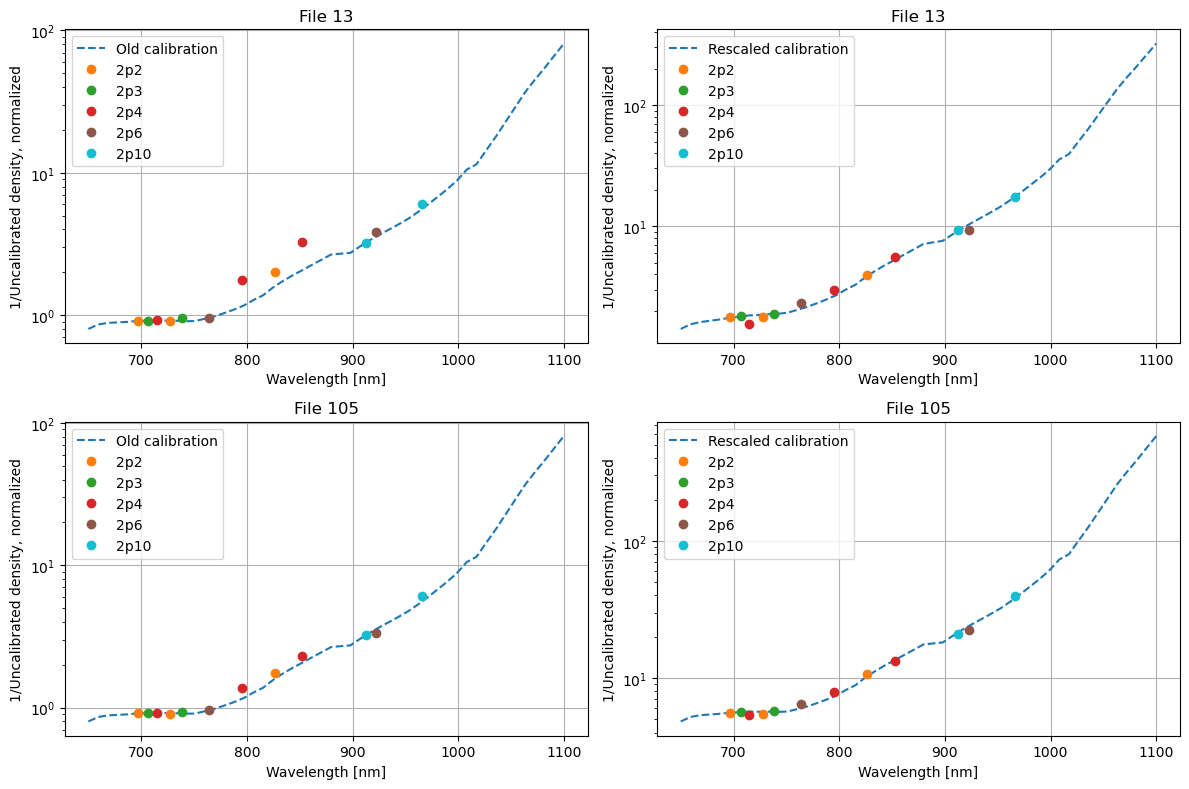

In [104]:
xs = np.linspace( 650, 1100 )
polydeg = 1

splt.init( len( data ), 2 )

file = "CalibrationData/Calib_20250204_FCUVIR600.csv"

calib_spectrum = pd.read_csv(file, index_col = False).to_dict('list')
theocal = np.log10( np.interp( xs, calib_spectrum['wl'], calib_spectrum['f_normalized'] ) )


def calfunc( xxx, *pars ):
    return [
        pars[ int(x[0]) + polydeg + 1 ] + np.interp( x[1], xs, theocal ) + np.polyval( pars[:polydeg+1], x[1] ) for x in xxx
    ]

for d in data:
    splt.next()

    plt.plot( xs, 10**theocal, '--', label ="Old calibration" )

    xf = []
    yf = []
    i = 0
    levs = {}

    for lv in d['den_dict'].keys():
        if( len( d['den_dict'][lv] ) > 1 ):
            wls = [ l['wl'] for l in d['den_dict'][lv] ]
            kkk = - np.log10( np.array( [ l['den'] for l in d['den_dict'][lv] ] ) )
            kkk_resc = kkk + ( np.interp( wls[0], xs, theocal ) - kkk[0] )

            
            plt.plot( wls, 10**kkk_resc, 'o', color = colors[ lv ], label = lv )

            for wl, kk in zip( wls, kkk ):
                xf.append( ( i, wl ) )
                yf.append( kk )
            levs[i] = lv
            i += 1
    
    plt.legend( loc = 'upper left')
    plt.xlabel("Wavelength [nm]")
    plt.ylabel("1/Uncalibrated density, normalized")
    plt.yscale('log')
    plt.title(f"File {d['ID']}")


    splt.next()
    p,_ = curve_fit( calfunc, xf, yf, p0 = [ *np.full( polydeg, 0 ), 0, *np.full( i, 2 ) ], bounds=(
        ( [ *np.full( polydeg, -1 ), -100, *np.full( i, 0 ) ],
        [ *np.full( polydeg, 1 ), 100, *np.full( i, 5 ) ] )
    ) )
    print( p )

    plt.plot( xs,10**( theocal + np.polyval( p[:polydeg+1], xs ) ), '--', label ="Rescaled calibration" )
    for x, y in zip( xf, yf ):
        plt.plot( x[1], 10**( y - p[ x[0] + polydeg +1]), 'o', color = colors[levs[ x[0] ]])
    for lv in levs.values():
        plt.plot( [],[], 'o', label = lv, color = colors[lv] )

    plt.yscale('log')
    plt.legend( loc = 'upper left')
    plt.xlabel("Wavelength [nm]")
    plt.ylabel("1/Uncalibrated density, normalized")
    plt.title(f"File {d['ID']}")

    plt.tight_layout()

    pd.DataFrame.from_dict( { 'wl': xs, 'f_normalized': 10**( theocal * np.polyval( p[:polydeg+1], xs ) )} ).to_csv(f"CalCorrected/{file[16:-4]}_dataset{d['ID']}_poly{polydeg}.csv")
